In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import ttest_ind

CUPED (Controlled-experiment Using Pre-Experiment Data) — зменшення дисперсії в A/B тесті

- Ідея: скоригувати метрику під час експерименту на ту саму метрику **до** старту тесту.
- Формула: `Y_cuped = Y - θ * (X - mean(X))`, де `X` — pre-experiment коваріата, `θ = cov(Y, X) / var(X)`.
- Оцінка ефекту залишається незміщеною (у рандомізованому A/B), а дисперсія падає, якщо `X` добре корелює з `Y`.
- Типові коваріати: revenue / sessions / deposits за попередній період, historical LTV, baseline conversion.

In [2]:
def cuped_ab_test(
    df,
    target_col='target',
    value_col='gross_summ',
    covariate_col='gross_summ_pre',
    alternative='two-sided',
    confidence_level=0.95
):
    """
    A/B-порівняння target vs control на CUPED-скорегованій метриці.

    Параметри
    ---------
    df : pandas.DataFrame
        Датафрейм з групою, метрикою експерименту та pre-experiment коваріатою.

    target_col : str, за замовчуванням 'target'
        Стовпець групи: 1 — target, 0 — control.

    value_col : str, за замовчуванням 'gross_summ'
        Метрика під час експерименту (outcome).

    covariate_col : str, за замовчуванням 'gross_summ_pre'
        Pre-experiment коваріата (та сама метрика до старту тесту).

    alternative : {'two-sided', 'greater', 'less'}, за замовчуванням 'two-sided'
        Тип t-тесту для різниці середніх (target − control).

    confidence_level : float, за замовчуванням 0.95
        Рівень довіри для CI різниці середніх.

    Повертає
    --------
    pandas.DataFrame
        Один рядок з результатами CUPED A/B:
        - Metric / Covariate
        - Mean Difference, Mean Target, Mean Control (по CUPED)
        - CI Lower / CI Upper (Welch, через scipy)
        - T-test p-value, Theta, Corr(Y, X), N Target / N Control

    Приклади
    --------
    >>> cuped_ab_test(df, value_col='gross_summ', covariate_col='gross_summ_pre')
    """
    data = df[[target_col, value_col, covariate_col]].dropna().copy()
    y = data[value_col].astype(float)
    x = data[covariate_col].astype(float)

    theta = np.cov(y, x, ddof=1)[0, 1] / np.var(x, ddof=1)
    cuped_col = f"{value_col}_cuped"
    data[cuped_col] = y - theta * (x - x.mean())

    tr = data.loc[data[target_col] == 1, cuped_col]
    co = data.loc[data[target_col] == 0, cuped_col]

    ttest = ttest_ind(tr, co, equal_var=False, alternative=alternative)
    ci = ttest.confidence_interval(confidence_level=confidence_level)

    return pd.DataFrame([{
        'Metric': value_col,
        'Covariate': covariate_col,
        'Mean Difference': round(tr.mean() - co.mean(), 4),
        'Mean Target': round(tr.mean(), 4),
        'Mean Control': round(co.mean(), 4),
        'CI Lower': round(ci.low, 4),
        'CI Upper': round(ci.high, 4),
        'T-test p-value': round(ttest.pvalue, 4),
        'Theta': round(theta, 4),
        'Corr(Y, X)': round(np.corrcoef(y, x)[0, 1], 4),
        'N Target': len(tr),
        'N Control': len(co),
    }])

In [3]:
def plot_cuped(
    df,
    target_col='target',
    value_col='gross_summ',
    covariate_col='gross_summ_pre'
):
    """
    Візуалізація CUPED: outcome vs pre-метрика та розподіл CUPED по групах.

    Параметри
    ---------
    df : pandas.DataFrame
        Той самий датафрейм, що й для cuped_ab_test.

    target_col / value_col / covariate_col : str
        Назви стовпців групи, outcome та pre-метрики.
    """
    data = df[[target_col, value_col, covariate_col]].dropna().copy()
    y = data[value_col].astype(float)
    x = data[covariate_col].astype(float)

    theta = np.cov(y, x, ddof=1)[0, 1] / np.var(x, ddof=1)
    corr_yx = np.corrcoef(y, x)[0, 1]
    cuped_col = f"{value_col}_cuped"
    data[cuped_col] = y - theta * (x - x.mean())

    tr = data.loc[data[target_col] == 1, cuped_col]
    co = data.loc[data[target_col] == 0, cuped_col]
    mean_diff = tr.mean() - co.mean()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    for group_val, label, color in [(0, 'control', 'steelblue'), (1, 'target', 'darkorange')]:
        mask = data[target_col] == group_val
        axes[0].scatter(
            data.loc[mask, covariate_col],
            data.loc[mask, value_col],
            c=color, alpha=0.45, s=18, label=label
        )

    axes[0].set_xlabel(covariate_col)
    axes[0].set_ylabel(value_col)
    axes[0].set_title(f'Outcome vs pre-метрика (corr={corr_yx:.2f}, θ={theta:.2f})')
    axes[0].legend(title='Група')
    axes[0].grid(alpha=0.25)

    axes[1].hist(co, bins=30, density=True, alpha=0.55, color='steelblue', label='control', edgecolor='black')
    axes[1].hist(tr, bins=30, density=True, alpha=0.55, color='darkorange', label='target', edgecolor='black')
    axes[1].axvline(co.mean(), color='steelblue', linestyle='--', linewidth=2)
    axes[1].axvline(tr.mean(), color='darkorange', linestyle='--', linewidth=2)
    axes[1].set_xlabel(cuped_col)
    axes[1].set_title(f'CUPED: Δ={mean_diff:.3f}')
    axes[1].legend(title='Група')
    axes[1].grid(alpha=0.25)

    plt.tight_layout()
    plt.show()

### демо

Симулюємо A/B по `gross_summ`: сильна кореляція з `gross_summ_pre` + невеликий uplift у target.

In [4]:
rng = np.random.default_rng(42)
n = 2000

gross_summ_pre = rng.normal(50, 15, size=n)
noise = rng.normal(0, 8, size=n)
target = rng.integers(0, 2, size=n)
true_uplift = 2.0

gross_summ = 0.75 * gross_summ_pre + noise + true_uplift * target

df = pd.DataFrame({
    'user_id': np.arange(n),
    'target': target,
    'gross_summ': gross_summ,
    'gross_summ_pre': gross_summ_pre,
})

df.head()

,user_id,target,gross_summ,gross_summ_pre
0,0,0,37.312459,54.570756
1,1,0,20.473157,34.400238
2,2,0,49.414655,61.256768
3,3,0,50.096188,64.108471
4,4,0,4.312522,20.734472


In [5]:
cuped_ab_test(
    df,
    target_col='target',
    value_col='gross_summ',
    covariate_col='gross_summ_pre'
)

,Metric,Covariate,Mean Difference,Mean Target,Mean Control,CI Lower,CI Upper,T-test p-value,Theta,"Corr(Y, X)",N Target,N Control
0,gross_summ,gross_summ_pre,2.0888,39.0527,36.9639,1.389,2.7887,0.0,0.7523,0.815,1009,991


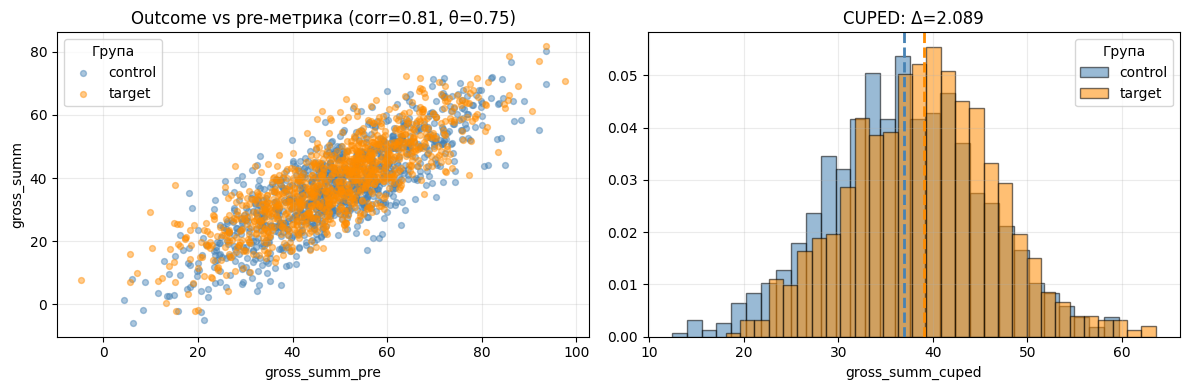

In [6]:
plot_cuped(
    df,
    target_col='target',
    value_col='gross_summ',
    covariate_col='gross_summ_pre'
)